In [24]:
pip install obspy numpy scipy scikit-learn matplotlib torch tqdm


Note: you may need to restart the kernel to use updated packages.


In [25]:
# 1. CUDA Setup and Device Management
import torch
import numpy as np
import random

def setup_cuda(seed=0, deterministic=False):
    """Set up global device and initialize random seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        device = torch.device("cuda")  # Check for GPU availability
        print("Using CUDA:", torch.cuda.get_device_name(0))  # Output the GPU name
        torch.backends.cudnn.benchmark = not deterministic
        torch.backends.cudnn.deterministic = deterministic
    else:
        device = torch.device("cpu")  # Fallback to CPU if CUDA is unavailable
        print("CUDA not available, fallback to CPU")

    return device

device = setup_cuda(seed=0, deterministic=False)

def to_device(x, device=device):
    """Move data to CUDA (or CPU) recursively for tensor/numpy/list/tuple/dict."""
    if torch.is_tensor(x):
        return x.to(device, non_blocking=True)  # Move tensor to device
    if isinstance(x, np.ndarray):
        return torch.from_numpy(x).to(device, non_blocking=True)  # Convert numpy to tensor
    if isinstance(x, (list, tuple)):
        return type(x)(to_device(v, device) for v in x)  # Recursive call for lists/tuples
    if isinstance(x, dict):
        return {k: to_device(v, device) for k, v in x.items()}  # Recursive call for dictionaries
    return x


Using CUDA: NVIDIA GeForce RTX 4060 Laptop GPU


In [26]:
# 2. Loading and Checking mseed Data
import os
from obspy import read

def load_and_check_mseed_data(directory_path):
    """Load and display basic information about mseed files."""
    for filename in os.listdir(directory_path):
        if filename.endswith(".mseed"):
            file_path = os.path.join(directory_path, filename)
            print(f"\nReading {filename}...\n")
            
            # Use obspy to read the mseed file
            st = read(file_path)
            
            # Print stream information
            print("Stream Information:")
            print(st)
            
            # Print detailed information for each trace (each channel)
            for tr in st:
                print("\nTrace Information:")
                print(tr)
                
                # Print data type and length of the signal
                print(f"Data type: {tr.data.dtype}")
                print(f"Data length: {len(tr.data)}")
                print(f"Start time: {tr.stats.starttime}")
                print(f"End time: {tr.stats.endtime}")
                print(f"Sampling rate: {tr.stats.sampling_rate}")
                print(f"Channel name: {tr.stats.channel}")
                print(f"Station name: {tr.stats.station}")


In [27]:
# 3. Loading Data from mseed Files
def load_mseed_folder(folder_path, channel_whitelist=None, target_fs=100.0):
    """
    folder_path: Path to the directory containing mseed files
    channel_whitelist: List of channels to retain, e.g., ["EHE", "EHN", "EHZ"]
    target_fs: Target sampling rate, default is 100Hz
    """
    # Get all mseed files in the folder
    files = [os.path.join(folder_path, f) for f in os.listdir(folder_path)
             if f.lower().endswith((".mseed", ".msd", ".miniseed"))]
    
    # If no mseed files are found, raise an error
    if len(files) == 0:
        raise FileNotFoundError(f"No mseed files found in the folder ({folder_path})")
    
    # Initialize the stream object
    st = None
    for fp in files:
        try:
            s = read(fp)  # Read the mseed file
            st = s if st is None else (st + s)
            print(f"Loaded file: {fp}, contains {len(s)} traces")
        except Exception as e:
            print(f"Error reading file {fp}: {e}")
    
    # If no data was loaded, raise an error
    if len(st) == 0:
        raise ValueError("Loaded mseed data is empty. Please check the files.")
    
    # Print available channels
    print(f"Loaded {len(st)} traces from {len(files)} files.")
    available_channels = [tr.stats.channel for tr in st]
    print(f"Available channels: {available_channels}")

    # Select channels based on whitelist
    if channel_whitelist is not None:
        available_channels_lower = [ch.lower() for ch in available_channels]
        channel_whitelist_lower = [ch.lower() for ch in channel_whitelist]
        matching_channels = [ch for ch in channel_whitelist_lower if ch in available_channels_lower]

        if not matching_channels:
            raise ValueError("No matching channels found. Please check the channel whitelist.")
        
        # Update the selected channels
        st = st.select(channel="|".join(matching_channels))

    # Merge segments of the same channel
    st.merge(method=1, fill_value="interpolate")

    # Resample to the target sampling rate (100Hz)
    for tr in st:
        if abs(tr.stats.sampling_rate - target_fs) > 1e-6:
            tr.resample(target_fs)

    # Trim data to align the same time period across all traces
    if len(st) > 0:
        t0 = max(tr.stats.starttime for tr in st)
        t1 = min(tr.stats.endtime for tr in st)
        st.trim(t0, t1)

    return st


In [28]:
# 4. Segmenting the Data into 1-Second Intervals
def segment_stream_1s(stream, fs=100):
    """Segment the data into 1-second intervals."""
    stream_sorted = sorted(stream, key=lambda tr: tr.stats.channel)  # Sort by channel name
    channel_names = [tr.stats.channel for tr in stream_sorted]

    # Find the minimum length of all traces to ensure equal lengths
    min_len = min(len(tr.data) for tr in stream_sorted)
    min_len = (min_len // fs) * fs  # Ensure it's a multiple of fs

    data = []
    for tr in stream_sorted:
        x = tr.data[:min_len].astype(np.float32)  # Trim or pad data to the target length
        x = x.reshape(-1, fs)  # Reshape to (N, fs)
        data.append(x)

    # Stack the data into a 3D array (N, C, fs) where N is the number of samples, C is the number of channels
    segments = np.stack(data, axis=0).transpose(1,0,2)  # (N, C, fs)
    return segments, channel_names


In [6]:
def hjorth_params_1segment(x, eps=1e-8):
    """
    计算单个时间片段的 Hjorth 特征
    x: 输入信号数据
    eps: 一个小常数，用于防止除零错误
    """
    x = x.astype(np.float32)
    dx = np.diff(x, prepend=x[0])  # 一阶差分（速度）
    ddx = np.diff(dx, prepend=dx[0])  # 二阶差分（加速度）

    m0 = np.mean(x**2)
    m2 = np.mean(dx**2)
    m4 = np.mean(ddx**2)

    activity = m0
    mobility = np.sqrt((m2 + eps) / (m0 + eps))
    complexity = np.sqrt((m4 + eps) / (m2 + eps)) / (mobility + eps)
    return activity, mobility, complexity

def compute_hjorth_features(segments):
    """
    计算每个时间片段的 Hjorth 特征，返回所有片段的特征值
    segments: 输入的信号数据，形状为 (N, C, fs)
    """
    N, C, fs = segments.shape
    hjorth = np.zeros((N, C, 3), dtype=np.float32)  # 每个通道计算3个Hjorth特征
    for i in range(N):
        for c in range(C):
            hjorth[i, c, :] = hjorth_params_1segment(segments[i, c, :])
    flat24 = hjorth.reshape(N, -1)  # 扁平化成 (N, 24)，每个时间片段对应24个特征
    return hjorth, flat24


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ========================================
# 6. 数据划分（80/20）并标准化
# ========================================
def split_and_scale_per_param(hjorth_normal, test_size=0.2, random_state=0):
    """
    将 Hjorth 特征数据划分为训练集和测试集，并对每个特征进行标准化
    hjorth_normal: 输入的正常数据（形状为 N x 9）
    test_size: 测试集比例，默认 20%
    random_state: 随机种子
    """
    Xtr_list, Xte_list, scaler_list = [], [], []
    for p in range(3):  # 对每个特征（activity、mobility、complexity）分别进行处理
        Xp = hjorth_normal[:, :, p]  # (N, 8) 获取当前参数的所有数据
        Xtr, Xte = train_test_split(Xp, test_size=test_size, random_state=random_state, shuffle=True)

        # 标准化训练集和测试集
        scaler = StandardScaler().fit(Xtr)
        Xtr_s = scaler.transform(Xtr).astype(np.float32)
        Xte_s = scaler.transform(Xte).astype(np.float32)

        Xtr_list.append(Xtr_s)
        Xte_list.append(Xte_s)
        scaler_list.append(scaler)

    return Xtr_list, Xte_list, scaler_list


In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull

# ========================================
# 7. PCA + Convex Hull 可视化
# ========================================
def plot_pca_with_hull(X8, labels=None, title="PCA"):
    """
    对数据进行 PCA 降维并使用 Convex Hull 包围数据点，进行二维可视化
    X8: 输入的特征数据，形状为 (N, 8)
    labels: 数据标签（可选，用于颜色区分）
    title: 图表标题
    """
    pca = PCA(n_components=2)
    Z = pca.fit_transform(X8)

    plt.figure()
    if labels is None:
        plt.scatter(Z[:, 0], Z[:, 1], s=6)
    else:
        plt.scatter(Z[:, 0], Z[:, 1], c=labels, s=6, cmap="tab10")

    # 使用凸包包围数据点
    if len(Z) >= 3:
        hull = ConvexHull(Z)
        for simplex in hull.simplices:
            plt.plot(Z[simplex, 0], Z[simplex, 1], "k-", linewidth=1)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()


In [11]:
def plot_hjorth_three_pcas(
    hjorth,                # (N, C, 3)
    labels=None,
    label_names=None,
    sample_size=3000,
    random_state=0,
    standardize=True,
):
    """
    对 Hjorth 三个参数（活动度、流动性、复杂度）分别进行 PCA 和 Convex Hull 可视化
    hjorth: Hjorth 特征数据，形状为 (N, C, 3)
    labels: 数据标签（可选，用于颜色区分）
    sample_size: 可视化时选择的样本大小
    random_state: 随机种子
    standardize: 是否标准化数据
    """
    hjorth = np.asarray(hjorth)
    if hjorth.ndim != 3 or hjorth.shape[2] != 3:
        raise ValueError(f"hjorth 必须是 (N, C, 3) 的形状，当前形状为 {hjorth.shape}")

    # 分别提取活动度、流动性、复杂度的特征数据
    X_act = hjorth[:, :, 0]
    X_mob = hjorth[:, :, 1]
    X_com = hjorth[:, :, 2]

    # 标准化数据（如果需要）
    if standardize:
        X_act = _zscore(X_act)
        X_mob = _zscore(X_mob)
        X_com = _zscore(X_com)

    print("活动度矩阵:", X_act.shape)
    print("流动性矩阵:", X_mob.shape)
    print("复杂度矩阵:", X_com.shape)

    # 分别绘制三个 Hjorth 参数的 PCA + Convex Hull 可视化
    plot_pca_with_hull_sample(
        X_act,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Activity (sampled)"
    )

    plot_pca_with_hull_sample(
        X_mob,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Mobility (sampled)"
    )

    plot_pca_with_hull_sample(
        X_com,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Complexity (sampled)"
    )


In [12]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ========================================
# 9. 自编码器模型（AE9）
# ========================================
class AE9(nn.Module):
    def __init__(self, latent=3, hidden=16):
        """
        构建自编码器模型（AE9），包含编码器和解码器
        latent: 潜在空间的维度
        hidden: 隐藏层的神经元数量
        """
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(9, hidden), nn.ReLU(),
            nn.Linear(hidden, latent)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden), nn.ReLU(),
            nn.Linear(hidden, 9)
        )

    def forward(self, x):
        z = self.encoder(x)
        xhat = self.decoder(z)
        return xhat

def train_one_ae(Xtr, Xte, epochs=50, batch_size=256, lr=1e-3, device=device,
                 latent=3, hidden=16):
    """
    训练自编码器（AE9），用于学习正常数据的特征
    Xtr, Xte: 训练集和测试集数据（形状为 N x 9）
    """
    model = AE9(latent=latent, hidden=hidden).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()

    # 转换为 tensor
    tr_ds = TensorDataset(torch.from_numpy(Xtr).float())
    te_ds = TensorDataset(torch.from_numpy(Xte).float())

    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,
                           pin_memory=True)
    te_loader = DataLoader(te_ds, batch_size=batch_size, shuffle=False,
                           pin_memory=True)

    for ep in range(1, epochs + 1):
        # ---- 训练阶段 ----
        model.train()
        tr_loss = 0.0
        for (xb_cpu,) in tr_loader:
            xb = to_device(xb_cpu, device)
            xhat = model(xb)
            loss = loss_fn(xhat, xb)

            opt.zero_grad()
            loss.backward()
            opt.step()

            tr_loss += loss.item() * xb.size(0)
        tr_loss /= len(tr_loader.dataset)

        # ---- 测试阶段 ----
        model.eval()
        te_loss = 0.0
        with torch.no_grad():
            for (xb_cpu,) in te_loader:
                xb = to_device(xb_cpu, device)
                xhat = model(xb)
                te_loss += loss_fn(xhat, xb).item() * xb.size(0)
        te_loss /= len(te_loader.dataset)

        if ep % 10 == 0 or ep == 1:
            print(f"Epoch {ep:03d} | 训练 MAE {tr_loss:.6f} | 测试 MAE {te_loss:.6f}")

    return model


In [13]:
def reconstruction_errors(models, scalers, hjorth_all, device=device):
    """
    计算输入数据的重构误差
    models: 已训练的自编码器模型
    scalers: 每个特征的标准化器
    hjorth_all: 输入的所有 Hjorth 特征数据
    """
    N = hjorth_all.shape[0]
    errors = np.zeros((N, 3), dtype=np.float32)

    for p in range(3):
        Xp = hjorth_all[:, :, p]  # 获取当前参数的所有数据
        Xp_s = scalers[p].transform(Xp).astype(np.float32)  # 标准化数据

        xb = to_device(Xp_s, device)  # 转换为 torch tensor
        models[p].eval()
        with torch.no_grad():
            xhat = models[p](xb).detach().cpu().numpy()  # 重构数据

        errors[:, p] = np.mean(np.abs(Xp_s - xhat), axis=1)
    return errors


In [14]:
# ========================================
# 11. CUSUM算法：均值变化检测
# ========================================
def cusum_mean_change(errors_1d, mu0, sigma0, alpha=0.01, mu1_ratio=1.025):
    """
    CUSUM 算法：用于检测均值变化（即异常点）
    errors_1d: 输入的误差序列（形状为 N，表示每一时刻的误差）
    mu0, sigma0: 正常期的均值和标准差
    alpha: 灵敏度参数，控制假报警的概率，默认为 0.01
    mu1_ratio: 预期均值的变化比例，默认为 1.025，表示如果均值变化超过 2.5% 就认为发生异常
    返回:
      W: 递推统计量序列
      alarm: 是否发生异常的布尔标记（True 表示异常）
    """
    eps = 1e-8  # 防止除零错误
    mu1 = mu1_ratio * mu0  # 基于 mu0 计算新的均值 mu1
    delta = (mu1 - mu0) / (sigma0 + eps)  # 计算 CUSUM 参数：均值变化量

    C1 = delta  # C1 系数
    C3 = delta ** 2 / 2.0  # C3 系数
    h = -np.log(alpha)  # 根据 alpha 计算阈值 h，控制假报警率

    W = np.zeros_like(errors_1d, dtype=np.float32)  # 初始化递推统计量
    alarm = np.zeros_like(errors_1d, dtype=bool)  # 初始化报警标记

    w = 0.0  # 初始化递推统计量 w
    for t, e in enumerate(errors_1d):
        Y = (e - mu0) / (sigma0 + eps)  # 计算标准化误差
        S = C1 * Y - C3  # 计算每个时刻的变化量
        w = max(0.0, w + S)  # 递推更新 W
        W[t] = w
        alarm[t] = (w >= h)  # 当 W 超过阈值 h 时，标记为异常

    return W, alarm


In [16]:
def run_cusum_all(errors, errors_normal, alpha=0.01):
    """
    对所有参数运行 CUSUM 算法（均值变化检测）
    errors: 所有样本的误差
    errors_normal: 正常状态下的误差（用于计算均值和标准差）
    alpha: 灵敏度参数，默认值为 0.01
    返回:
      W_all: 所有参数的累积统计量
      A_all: 异常标记
    """
    W_all = []  # 存储所有参数的累积和
    A_all = []  # 存储所有参数的异常标记
    for p in range(3):  # 对于每个 Hjorth 参数（activity、mobility、complexity）
        mu0 = float(np.mean(errors_normal[:, p]))  # 正常状态的均值
        sigma0 = float(np.std(errors_normal[:, p]))  # 正常状态的标准差
        W, A = cusum_mean_change(errors[:, p], mu0, sigma0, alpha=alpha)  # 计算 CUSUM 结果
        W_all.append(W)  # 将累积统计量添加到 W_all
        A_all.append(A)  # 将异常标记添加到 A_all
    return np.stack(W_all, 1), np.stack(A_all, 1)


In [17]:
def fuzzy_health_state(alarms_3):
    """
    使用模糊逻辑对健康状态进行分类
    alarms_3: 输入的异常标记数组（形状为 N x 3），每个时刻有 3 个特征的异常标记
    返回：每秒的健康状态分类（绿色、黄色、橙色、红色）
    """
    out = []
    for t in range(len(alarms_3)):
        k = int(np.sum(alarms_3[t]))  # 计算每秒发生的异常数量（0~3）
        out.append(["green", "yellow", "orange", "red"][k])  # 根据异常数量确定健康状态
    return np.array(out)


In [18]:
def plot_health_timeline(states, title="Health timeline"):
    """
    可视化健康状态的时间线
    states: 健康状态分类数组（绿色、黄色、橙色、红色）
    title: 图表标题
    """
    mapping = {"green": 0, "yellow": 1, "orange": 2, "red": 3}  # 映射健康状态为数字
    states = np.asarray(states)

    if states.size == 0:
        raise ValueError("states 为空，检查 alarms_3 是否为空或生成失败")

    y = np.vectorize(mapping.get)(states)  # 将健康状态映射为数字

    fig, ax = plt.subplots(figsize=(12, 3))  # 绘制图形
    ax.plot(y, lw=1)
    ax.set_yticks([0, 1, 2, 3])  # 设置 y 轴的标签
    ax.set_yticklabels(["green", "yellow", "orange", "red"])  # 标签为绿色、黄色、橙色、红色
    ax.set_title(title)
    ax.set_xlabel("seconds")
    plt.show()  # 显示图形
    return fig, ax


健康状态长度: 3960 唯一状态: ['green' 'orange' 'yellow']


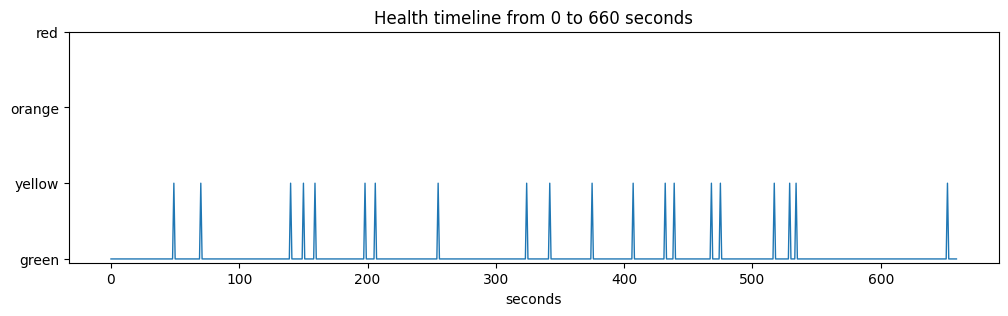

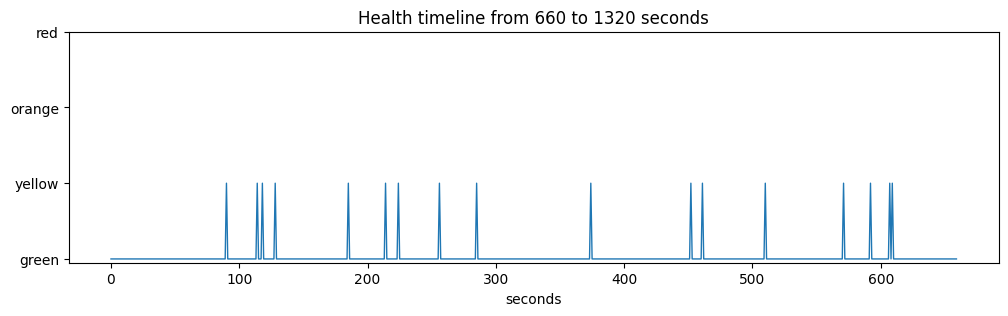

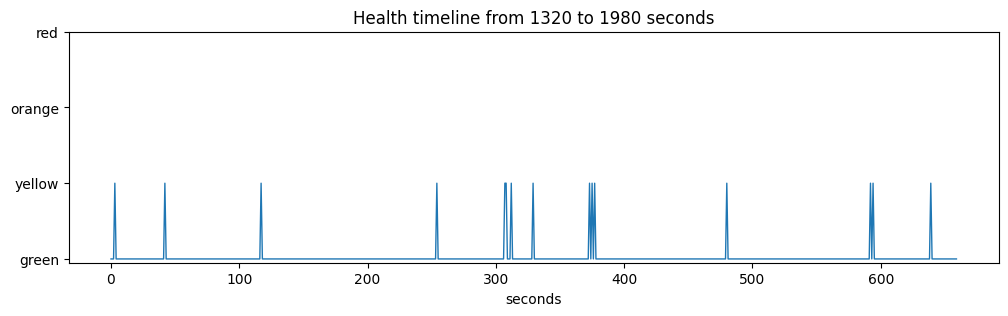

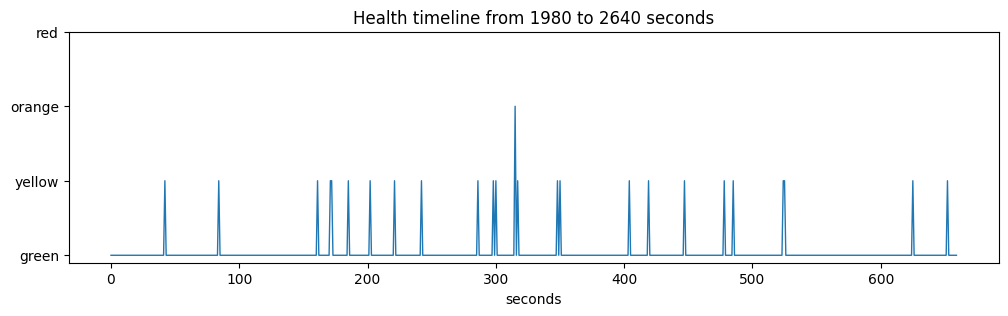

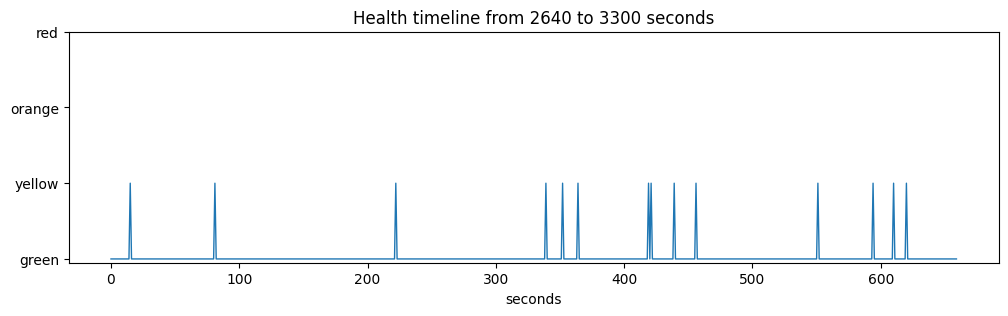

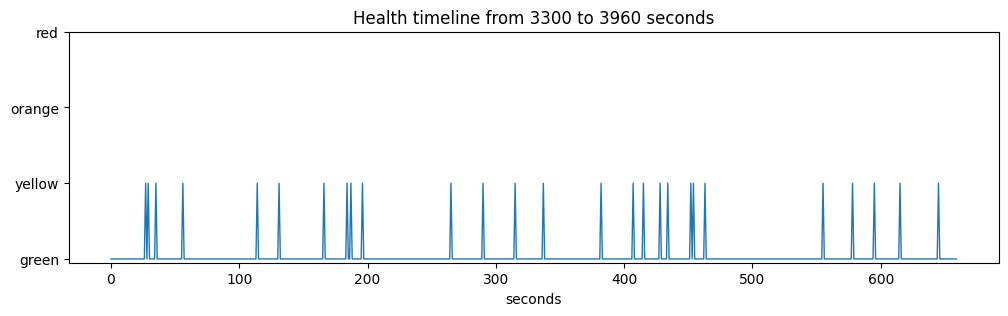

In [19]:
# 生成完整的 alarms_3 数据，数据时长为 3960 秒（1小时6分钟）
N = 3960  # 假设数据长度为 3960 秒（1小时6分钟）
alarms_3 = (np.random.rand(N, 3) > 0.99)  # 模拟报警：大约 1% 的概率报警（alpha = 0.01）

# 计算健康状态
states = fuzzy_health_state(alarms_3)
print("健康状态长度:", len(states), "唯一状态:", np.unique(states))

# 分段展示健康状态（每660秒分一个图，约 11 分钟）
step = 660  # 每660秒为一个图（11分钟）
for i in range(0, N, step):
    end_idx = min(i + step, N)
    states_segment = states[i:end_idx]
    plot_health_timeline(states_segment, title=f"Health timeline from {i} to {end_idx} seconds")


In [20]:
# ========================================
# 16. 生成器（GeneratorCNN1D）和判别器（DiscriminatorCNN1D）
# ========================================
class GeneratorCNN1D(nn.Module):
    def __init__(self, z_dim=64, out_len=100):
        super().__init__()
        # 将输入的噪声 z 映射到 128x25 维度
        self.fc = nn.Linear(z_dim, 128 * 25)
        self.deconv = nn.Sequential(
            nn.ConvTranspose1d(128, 64, kernel_size=4, stride=2, padding=1),  # 上采样，从 25 -> 50
            nn.ReLU(),
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=2, padding=1),   # 上采样，从 50 -> 100
            nn.ReLU(),
            nn.Conv1d(32, 1, kernel_size=3, padding=1)                        # 输出 (100,)
        )

    def forward(self, z):
        # 将 z 映射到特征空间
        x = self.fc(z)
        x = x.view(-1, 128, 25)  # 变形为 (B, 128, 25)
        x = self.deconv(x)  # 经过 deconv 层，得到最终的生成数据
        return x.squeeze(1)  # 去掉维度 1

class DiscriminatorCNN1D(nn.Module):
    def __init__(self, in_len=100):
        super().__init__()
        # 判别器的卷积层，逐渐缩小数据维度
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, stride=2, padding=2),  # 从 100 -> 50
            nn.LeakyReLU(0.2),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2), # 从 50 -> 25
            nn.LeakyReLU(0.2),
            nn.Conv1d(64, 128, kernel_size=5, stride=2, padding=2),# 从 25 -> 13
            nn.LeakyReLU(0.2),
        )
        self.fc = nn.Linear(128 * 13, 1)  # 通过全连接层输出一个值

    def forward(self, x):
        x = x.unsqueeze(1)  # 将输入的 (B, 100) 变为 (B, 1, 100) 以适应 Conv1d
        h = self.conv(x)  # 经过卷积层
        h = h.reshape(h.size(0), -1)  # 将输出展平
        return self.fc(h).view(-1)  # 输出判别结果


In [21]:
# ========================================
# 17. 物理损失（二次积分）
# ========================================
def double_integral_torch(acc, dt=0.01):
    """
    根据加速度信号计算位移（物理约束：加速度的二次积分）
    acc: 输入的加速度信号（形状为 N x T）
    dt: 时间步长，默认为 0.01
    返回：位移信号（形状为 N x T）
    """
    v = torch.cumsum(acc, dim=1) * dt  # 积分得到速度
    x = torch.cumsum(v, dim=1) * dt    # 积分得到位移
    x = x - x.mean(dim=1, keepdim=True)  # 去除漂移（使得位移以零为基准）
    return x


In [23]:
# ========================================
# 18. GAN训练损失（WGAN-GP + PINN）
# ========================================
from torch.utils.data import DataLoader

def gradient_penalty(D, real, fake, device=device):
    """
    计算梯度惩罚，用于 WGAN-GP 损失
    D: 判别器
    real: 真实数据
    fake: 生成数据
    返回：梯度惩罚值
    """
    B = real.size(0)  # 获取批次大小
    eps = torch.rand(B, 1, device=device).expand_as(real)  # 随机生成一个插值
    interp = (eps * real + (1 - eps) * fake).requires_grad_(True)  # 插值数据
    d_interp = D(interp)  # 判别器对插值数据的输出
    grads = torch.autograd.grad(
        d_interp, interp, torch.ones_like(d_interp),
        create_graph=True, retain_graph=True, only_inputs=True
    )[0]
    return ((grads.norm(2, dim=1) - 1) ** 2).mean()  # 计算梯度惩罚（WGAN-GP）

def train_gan_pinn(acc_samples, disp_samples, epochs=200, batch_size=256, z_dim=64, lr=1e-4, n_critic=5, lambda_gp=10.0, lambda_phys=20.0, device=device):
    """
    训练 WGAN-GP + PINN 网络（生成加速度信号并进行物理约束）
    acc_samples: 加速度样本
    disp_samples: 位移样本
    epochs: 训练的总轮数
    batch_size: 每批次的样本数
    z_dim: 输入噪声的维度
    lr: 学习率
    n_critic: 判别器更新的次数
    lambda_gp: 梯度惩罚的权重
    lambda_phys: 物理损失的权重
    返回：训练好的生成器 G 和判别器 D
    """
    dl = DataLoader(AccDispDataset(acc_samples, disp_samples), batch_size=batch_size, shuffle=True, drop_last=True, pin_memory=True)
    
    G = GeneratorCNN1D(z_dim=z_dim).to(device)  # 初始化生成器
    D = DiscriminatorCNN1D().to(device)  # 初始化判别器
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9))  # 生成器优化器
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.9))  # 判别器优化器

    for ep in range(1, epochs + 1):
        for acc_cpu, disp_cpu in dl:
            acc_real = to_device(acc_cpu)  # 将数据迁移到 CUDA
            disp_real = to_device(disp_cpu)  # 将数据迁移到 CUDA

            # 训练判别器 D
            for _ in range(n_critic):
                z = torch.randn(batch_size, z_dim, device=device)  # 生成噪声
                acc_fake = G(z).detach()  # 生成加速度信号并 detach（不计算梯度）
                lossD = D(acc_fake).mean() - D(acc_real).mean()  # 计算判别器的损失
                gp = gradient_penalty(D, acc_real, acc_fake)  # 计算梯度惩罚
                lossD_total = lossD + lambda_gp * gp  # 总损失包含梯度惩罚
                optD.zero_grad()  # 清空优化器梯度
                lossD_total.backward()  # 反向传播
                optD.step()  # 更新判别器

            # 训练生成器 G（包括 GAN 损失和物理约束）
            z = torch.randn(batch_size, z_dim, device=device)  # 生成噪声
            acc_fake = G(z)  # 生成加速度信号
            disp_fake = double_integral_torch(acc_fake, dt=0.01)  # 根据加速度信号计算位移

            lossG_gan = -D(acc_fake).mean()  # GAN 损失
            lossG_phys = ((disp_fake - disp_real) ** 2).mean()  # 物理损失（加速度和位移的差异）
            lossG = lossG_gan + lambda_phys * lossG_phys  # 总生成器损失

            optG.zero_grad()  # 清空优化器梯度
            lossG.backward()  # 反向传播
            optG.step()  # 更新生成器

        if ep % 10 == 0 or ep == 1:
            print(f"Epoch {ep:03d} | lossD {lossD.item():.4f} | lossG_gan {lossG_gan.item():.4f} | lossG_phys {lossG_phys.item():.6f}")

    return G, D
